0. Setup

In the section below, we install all required project dependencies.
In the first cell, we are installing [Ollama](https://ollama.com), the most popular way to build with open models.

In the next cell, we install all the Python dependencies needed for the study.

In [1]:
%%bash
sudo apt-get update &> /dev/null && curl -fsSL https://ollama.com/install.sh | sh

# In the terminal, run in two different tabs:
# ollama serve
# ollama run gemma4

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...


>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [6]:
%pip install -q "polars[gpu]" \
    spacy \
    seaborn \
    textstat \
    ollama \
    matplotlib \
    pyarrow \
    typing-extensions \
    pyarrow==24.0.0 \
    seaborn==0.13.2 \
    spacy==3.8.13 \
    textstat==0.7.13 \
    transformers==5.10.2 \
    click==8.0.4 \
    click-completion>=0.5.2 \
&& spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 97.2 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import re
import json
import numpy
import polars
import ollama
import spacy
import seaborn
import textstat
from pathlib import Path
from itertools import permutations
from matplotlib import pyplot
from capstone_lib import CapstoneLib 

os.chdir('/workspace/uol_capstone_project') 


1. CUAD Data loading

In [4]:
PATH_CUAD_PARQUET = Path("/workspace").rglob("**/*/0001_cuad_dataset.parquet")
PATH_CUAD_JSON = Path("/workspace").rglob("**/*/CUADv1.json")

CUAD_PARQUET = next(PATH_CUAD_PARQUET, None)
CUAD_JSON = next(PATH_CUAD_JSON, None)


if os.path.exists(CUAD_PARQUET):
    cuad_legal = CapstoneLib.load_parquet(CUAD_PARQUET)
    with open(CUAD_JSON) as cuad:
        cuad_json = json.load(cuad.buffer)

    legal_pieces = {}
    for data in cuad_json.get("data"):
        full_context = ""
        for paragraph in data.get("paragraphs"):
            if context := paragraph.get("context", ""):
                full_context += context
        legal_pieces[data.get("title")] = full_context


    cuad_legal = polars.DataFrame(legal_pieces)
    cuad_legal = cuad_legal.transpose(include_header=True)
    cuad_legal.columns = ["title", "paragraphs"]

    ### Parquet checkpoint
    cuad_legal.write_parquet("parquet_files/0001_cuad_dataset.parquet")



2. CUAD Data parsing

In [8]:
# Here we are trying to load cached file if it exists, otherwise we will need to reprocess everything
FILENAME = "cuad_sentence_extracted.parquet"
PATH_EXTRACTED_SENTENCES = Path(".").rglob(f"**/*/{FILENAME}")
CUAD_EXTRACTED = next(PATH_EXTRACTED_SENTENCES)

nlp = spacy.load("en_core_web_sm")

if os.path.exists(CUAD_EXTRACTED):
    cuad_legal = polars.read_parquet(CUAD_EXTRACTED)

else:
    cuad_legal = cuad_legal.with_columns(
        polars.col("paragraphs").map_elements(
            paragraphs_extractor, return_dtype=polars.List(polars.String)
        ).alias("paragraphs")
    )

    all_paragraphs = cuad_legal["paragraphs"].explode().to_list()
    docs = nlp.pipe(all_paragraphs, batch_size=64, n_process=4)
    clauses = [extract_clauses_from_doc(doc) for doc in docs]
    cuad_legal = cuad_legal.with_columns(
        polars.Series("sentences", clauses)
    )

    cuad_legal.write_parquet(f"parquet_files/{FILENAME}")

cuad_legal.head(5)

title,paragraphs,sentences
str,str,list[str]
"""LIMEENERGYCO_09_09_1999-EX-10-…","""EXHIBIT 10.6 …","[""exhibit 10.6 distributor agreement this distributor agreement (the ""agreement"") is made by and between electric city corp., a delaware corporation (""company"") and electric city of illinois llc (""distributor"") this 7th day of september, 1999. "", ""which is referred to as an ""energy saver"" which may be improved or otherwise changed from its present composition (the ""products"""", … ""in witness whereof the parties have executed this agreement as of the date first abovementioned. ""]"
"""WHITESMOKE,INC_11_08_2011-EX-1…","""Exhibit 10.26 CONFIDENTIAL …","[""exhibit 10.26 confidential treatment has been requested as to certain portions of this document."", ""which has been omitted herein and replaced with an asterisk"", … ""if the continued use of the primary application is conditioned on the other applications being installed and active on the end user's computer google confidential - 40""]"
"""LohaCompanyltd_20191209_F-1_EX…","""Exhibit 10.16 SUPPLY CONTRACT …","[""signed by the buyer and seller on , in hong kong"", ""general provisions 1.1"", … ""after signed by both parties""]"
"""CENTRACKINTERNATIONALINC_10_29…","""1 …","[""o 561.394-9773 fax 1733 avenida del sol, boca raton, florida, 33432 web site hosting agreement this web site hosting agreement (""this agreement"") is entered into this 6th day of april, 1999 by and between centrack international, a florida corporation (""the customer""), and i-on interactive, a florida corporation (""i-on""). definitions as used in this agreement"", ""i-on interactive, a florida corporation (""i-on""). definitions as used in this agreement"", … ""in witness whereof, the parties have executed this agreement as of the date first set forth above. ""]"
"""NELNETINC_04_08_2020-EX-1-JOIN…","""Exhibit 1 JOINT FILING AGREEM…","[""the undersigned hereby agree to jointly prepare and file with the applicable regulatory authorities this schedule 13g or schedule 13d and any future amendments thereto reporting each of the undersigned's ownership of securities of the issuer named herein, and hereby affirm that such schedule 13g or schedule 13d is being filed on behalf of each of the undersigned pursuant to and in accordance with the provisions of rule 13d-1(k) under the securities exchange act of 1934."", ""to jointly prepare and file with the applicable regulatory authorities"", … ""dated: march 27, 2020. ""]"


3. Applying metrics
    - Flesch-Kincaid Grade Level
    - Flesch Reading Ease
    - Gunning Fog Index
    - Dale-Chall Readability Score
    - LIX
    - Difficult Words Density

In [6]:
### Grading the text complexity
cuad_legal = cuad_legal.explode("sentences", empty_as_null=False)

cuad_legal = CapstoneLib.add_complexity_features(
    cuad_legal,
    nlp,

3b. Syntactic complexity features

These are computed from the same dependency relations used by `extract_clauses_from_doc`, and are deliberately orthogonal to the surface word-length metrics above.

- `clause_density` — clause markers per word (clause packing)
- `mdd` — mean dependency distance (processing load)
- `tree_depth` — maximum dependency tree depth (nesting)

In [3]:
# Parse unique clauses only, then join back on the clause text
FILENAME = "0002_cuad_dataset.parquet"
PATH_EXTRACTED_SENTENCES = Path(".").rglob(f"**/*/{FILENAME}")
CUAD_EXTRACTED = next(PATH_EXTRACTED_SENTENCES)

if os.path.exists(CUAD_EXTRACTED):
    cuad_legal = polars.read_parquet(CUAD_EXTRACTED)

else:
    unique_clauses = (
        cuad_legal["sentences"]
        .unique()
        .to_list()
    )
    
    docs = list(
        nlp.pipe(
            unique_clauses,
            batch_size=512,
            n_process=3,
        )
    )
    
    features = [
        CapstoneLib.syntax_features(doc)
        for doc in docs
    ]
    
    syntax_df = polars.DataFrame({
        "sentences": unique_clauses,
        "mdd": [f[0] for f in features],
        "tree_depth": [f[1] for f in features],
        "clause_density": [f[2] for f in features],
    })
    
    cuad_legal = cuad_legal.join(
        syntax_df,
        on="sentences",
        how="left"
    )
    
    cuad_legal.select(
        ["clause_density", "mdd", "tree_depth"]
    ).describe()
    
    cuad_legal.write_parquet(f"./parquet_files/{FILENAME}")

4. Data Visualisation

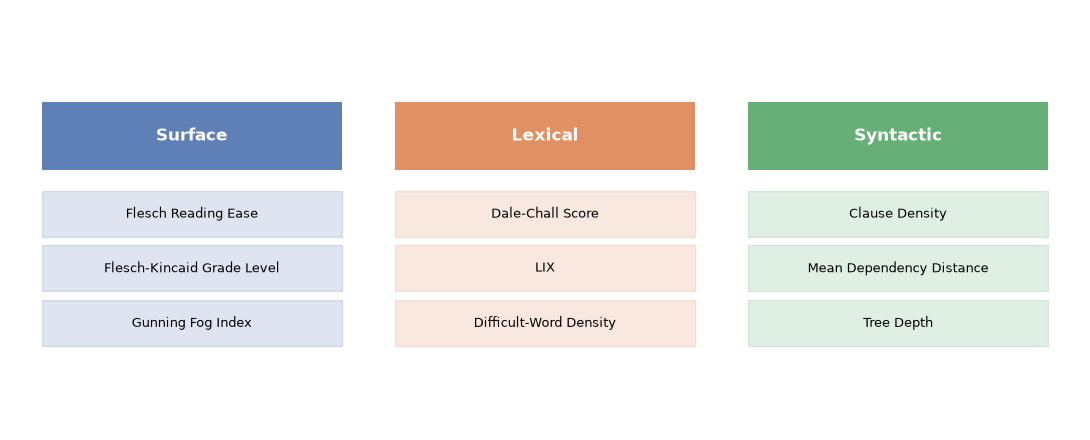

In [8]:
### Figure 2.1 — Feature taxonomy
# Readability metrics are grouped into three families by measurement basis. The surface family shares sentence length and word complexity as inputs and is therefore expected to be internally collinear; the lexical and syntactic families are constructed to be independent of it.

COLORS = {"Surface": "#4C72B0", "Lexical": "#DD8452", "Syntactic": "#55A868"}
FAMILIES = {
    "Surface":   ["Flesch Reading Ease", "Flesch-Kincaid Grade Level", "Gunning Fog Index"],
    "Lexical":   ["Dale-Chall Score", "LIX", "Difficult-Word Density"],
    "Syntactic": ["Clause Density", "Mean Dependency Distance", "Tree Depth"],
}

COLS = ["f_reading_ease", "fk_grade", "gunning_fog_idx",
        "dc_readability_score", "lix", "word_density"]
LABELS = dict(zip(COLS, [m for f in FAMILIES.values() for m in f]))

df = cuad_legal.select(COLS).to_pandas()
dfz = (df - df.mean()) / df.std()

fig, ax = pyplot.subplots(figsize=(11, 4.5))
ax.axis("off")
for i, (fam, items) in enumerate(FAMILIES.items()):
    x, c = 0.03 + i * 0.33, COLORS[fam]
    ax.add_patch(pyplot.Rectangle((x, 0.62), 0.28, 0.16, facecolor=c, alpha=0.9, edgecolor="none"))
    ax.text(x + 0.14, 0.70, fam, ha="center", va="center", color="white", fontsize=12, weight="bold")
    for j, item in enumerate(items):
        y = 0.46 - j * 0.13
        ax.add_patch(pyplot.Rectangle((x, y), 0.28, 0.11, facecolor=c, alpha=0.18, edgecolor=c))
        ax.text(x + 0.14, y + 0.055, item, ha="center", va="center", fontsize=9)

pyplot.tight_layout()
pyplot.savefig("./images/figure_taxonomy.png", dpi=300, bbox_inches="tight")
pyplot.show()

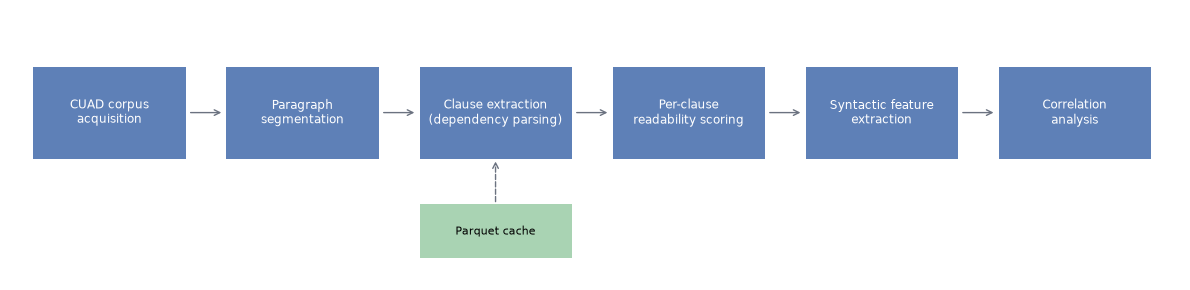

In [9]:
### Figure 3.1 — Artefact pipeline
# Six sequential stages from corpus acquisition to correlation analysis, with intermediate representations cached to Parquet for reproducibility.

stages = ["CUAD corpus\nacquisition", "Paragraph\nsegmentation", "Clause extraction\n(dependency parsing)",
          "Per-clause\nreadability scoring", "Syntactic feature\nextraction", "Correlation\nanalysis"]

fig, ax = pyplot.subplots(figsize=(12, 3))
ax.axis("off")
for i, label in enumerate(stages):
    x = 0.02 + i * 0.165
    ax.add_patch(pyplot.Rectangle((x, 0.45), 0.13, 0.34, facecolor="#4C72B0", alpha=0.9, edgecolor="none"))
    ax.text(x + 0.065, 0.62, label, ha="center", va="center", color="white", fontsize=8.5)
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + 0.163, 0.62), xytext=(x + 0.132, 0.62),
                    arrowprops=dict(arrowstyle="->", color="#6b7280"))
ax.add_patch(pyplot.Rectangle((0.35, 0.08), 0.13, 0.20, facecolor="#55A868", alpha=0.5, edgecolor="none"))
ax.text(0.415, 0.18, "Parquet cache", ha="center", va="center", fontsize=8)
ax.annotate("", xy=(0.415, 0.45), xytext=(0.415, 0.28),
            arrowprops=dict(arrowstyle="->", color="#6b7280", ls="--"))

pyplot.tight_layout()
pyplot.savefig("./images/figure_pipeline.png", dpi=300, bbox_inches="tight")
pyplot.show()

In [10]:
### Figure 4.1 — Dependency parse of the highest-LIX clause

# Clause heads (verb, dependency relation in the extraction set) are shown in their structural context.

worst = cuad_legal.sort("lix", descending=True)["sentences"][0]
doc = nlp(worst[:300])
spacy.displacy.render(doc, style="dep", jupyter=True)


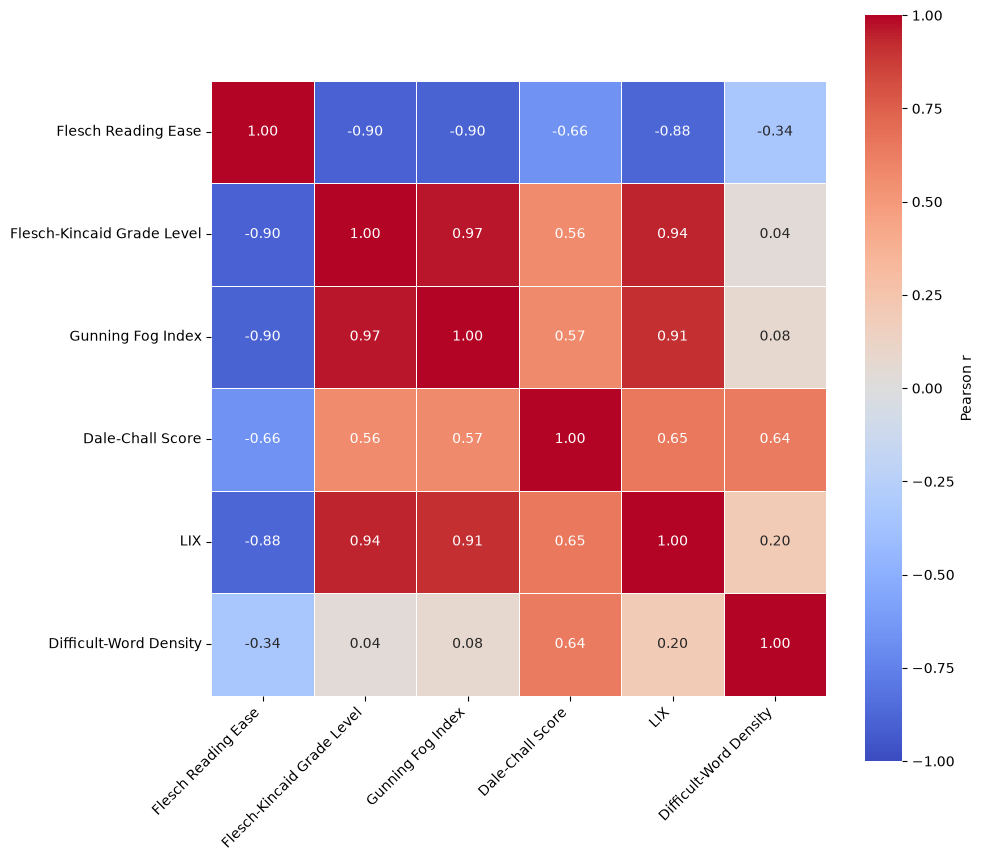

In [11]:
### Figure 5.1 — Pearson correlation across all nine features

# The surface family forms a high-correlation block (r up to 0.94), while the syntactic family remains largely uncorrelated with it.

corr = df.corr()

fig, ax = pyplot.subplots(figsize=(10, 9))
seaborn.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, linewidths=0.5,
                cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_xticklabels([LABELS[c] for c in COLS], rotation=45, ha="right")
ax.set_yticklabels([LABELS[c] for c in COLS])

pyplot.tight_layout()
pyplot.savefig("./images/figure_correlation.png", dpi=300, bbox_inches="tight")
pyplot.show()

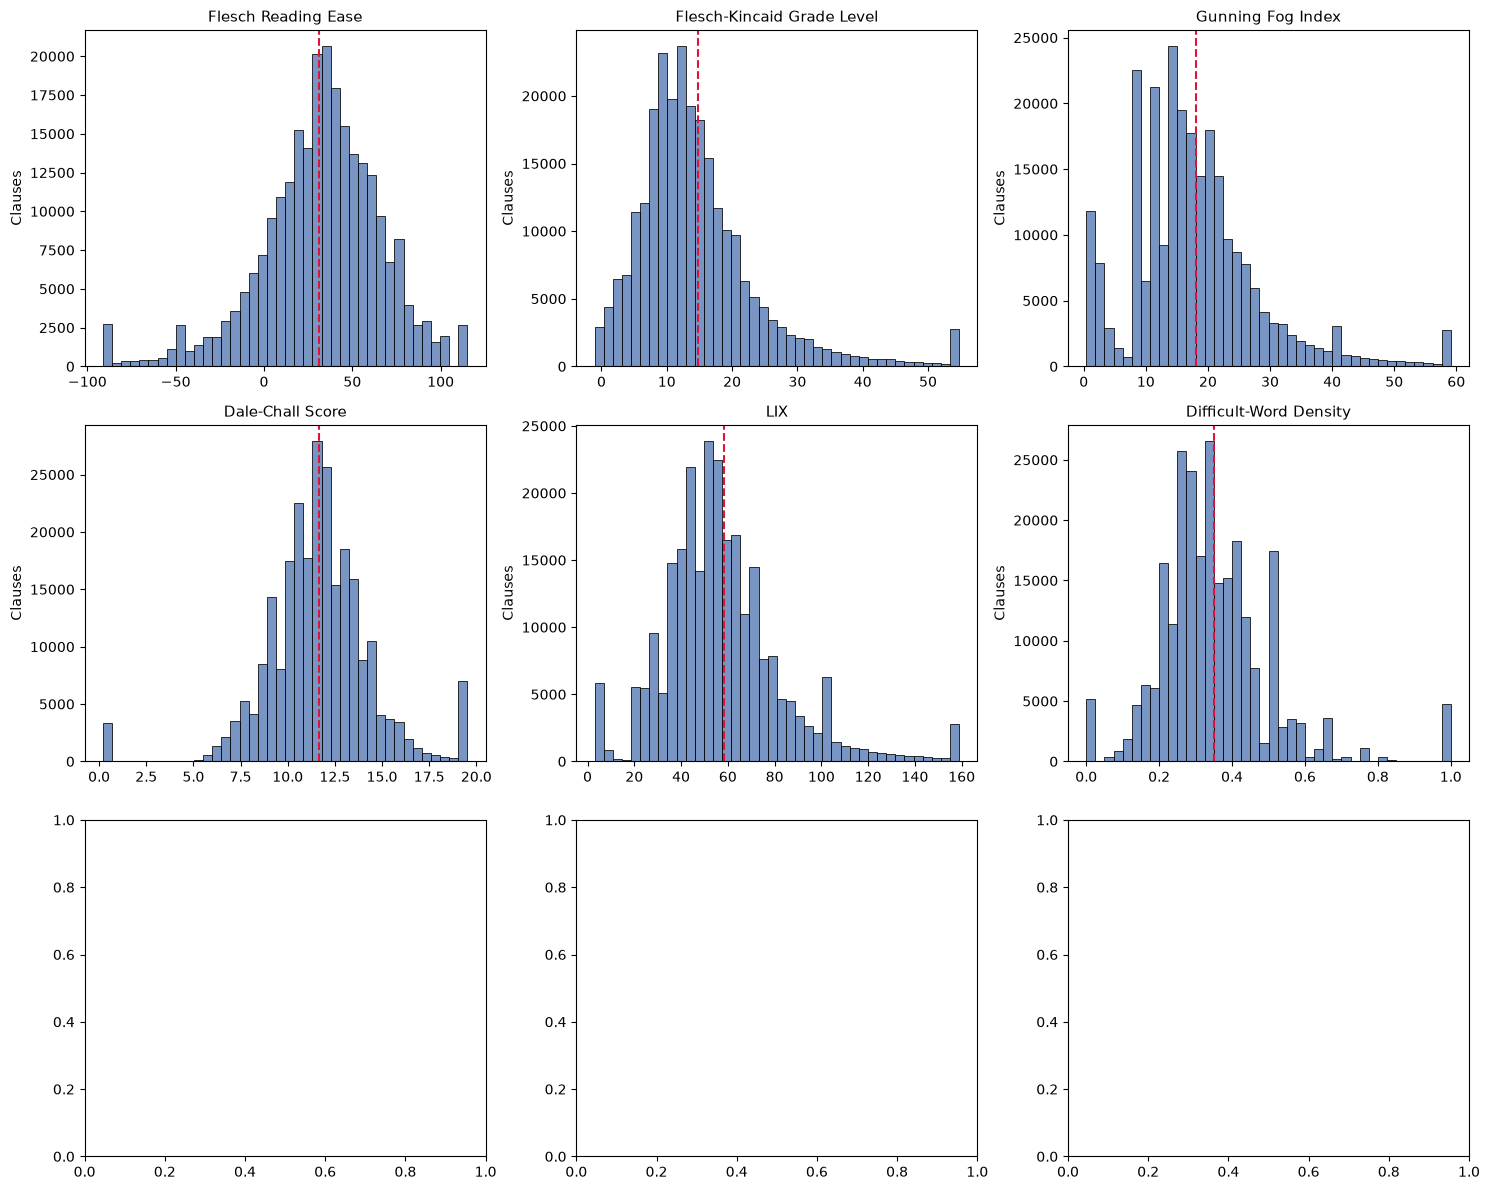

In [12]:
### Figure 5.2 — Distribution of each feature across CUAD clauses

# Dashed lines mark means; tails clipped to the 1st and 99th percentiles for display.

fig, axes = pyplot.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, COLS):
    data = df[col].dropna()
    lo, hi = data.quantile([0.01, 0.99])
    bins = range(0, int(data.max()) + 2) if col == "tree_depth" else 40
    seaborn.histplot(data.clip(lo, hi), bins=bins, color="#4C72B0", ax=ax)
    ax.axvline(data.mean(), color="crimson", ls="--")
    ax.set_title(LABELS[col], fontsize=11)
    ax.set_xlabel(""); ax.set_ylabel("Clauses")

pyplot.tight_layout()
pyplot.savefig("./images/figure_5_2_distributions.png", dpi=300, bbox_inches="tight")
pyplot.show()

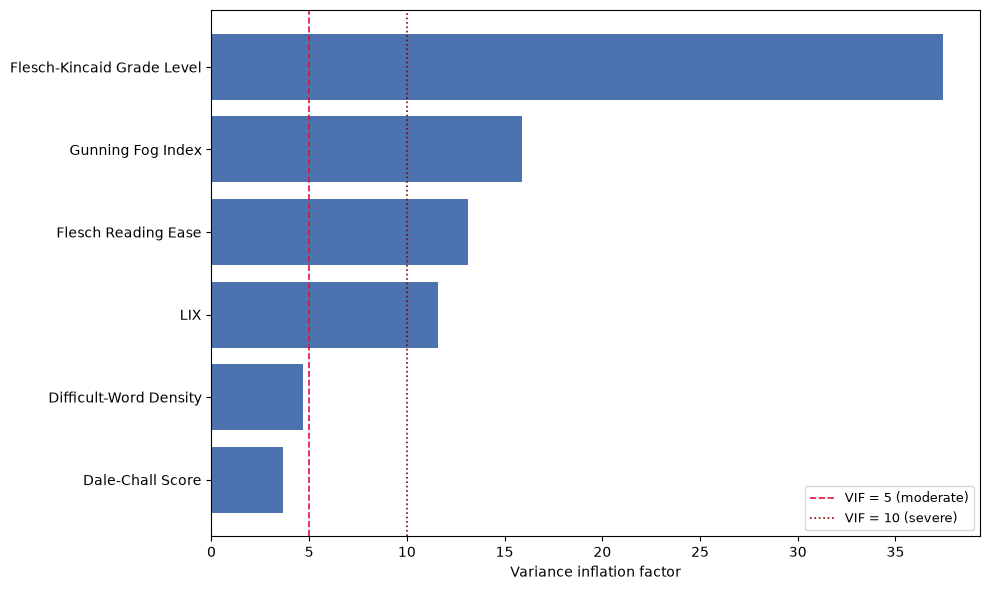

In [13]:
### Figure 6.1 — Variance inflation factor by feature

# Variance inflation factor for each of the nine features, computed from the inverse of the feature correlation matrix. Dashed lines mark the conventional thresholds of 5 (moderate collinearity) and 10 (severe). Values near 1 indicate a feature carrying largely independent information.
    
R = df.corr().values
vif = dict(zip(COLS, numpy.diag(numpy.linalg.inv(R))))

order = sorted(vif, key=vif.get, reverse=True)
vals = [vif[c] for c in order]

fig, ax = pyplot.subplots(figsize=(10, 6))
ax.barh([LABELS[c] for c in order], vals, color="#4C72B0")
ax.axvline(5, color="crimson", ls="--", lw=1.2, label="VIF = 5 (moderate)")
ax.axvline(10, color="darkred", ls=":", lw=1.2, label="VIF = 10 (severe)")
ax.set_xlabel("Variance inflation factor")
ax.set_ylabel("")
ax.legend(fontsize=9)
ax.invert_yaxis()

pyplot.tight_layout()
pyplot.savefig("./images/figure_variance_factor.png", dpi=300, bbox_inches="tight")
pyplot.show()

In [ ]:
# LLM Simplification

cuad_legal.with_columns(
    polars.col("sentences").map_elements(CapstoneLib.llm_call, return_dtype=polars.List(polars.String))
).alias("llm")

In [ ]:
cuad_legal.columns